# Proyek Analisis Data: [Input Nama Dataset]
- **Nama:** Laura Al Khansa
- **Email:** laura.al.khansa.tik24@stu.pnj.ac.id
- **ID Dicoding:** DS128B6X0909

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Pada jam-jam berapakah rata-rata jumlah penyewaan sepeda oleh pengguna registered mengalami lonjakan tertinggi (>300 peminjaman/jam) selama hari kerja (workingday) sepanjang tahun 2012?
- **Pertanyaan 2:** Seberapa besar persentase penurunan rata-rata jumlah penyewaan harian untuk kategori pengguna casual dibandingkan registered saat kondisi cuaca buruk (weathersit 3 atau 4) dibandingkan cuaca cerah (weathersit 1) selama periode 2011–2012?
- **Pertanyaan 2:** Musim manakah yang mencatat total akumulasi penyewaan sepeda tertinggi (cnt) sepanjang tahun 2011 dan apakah kenaikan tersebut memiliki korelasi linier dengan peningkatan rata-rata suhu (temp) di atas 0.6 (skor normalisasi)?

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style='darkgrid')

## Data Wrangling

### Gathering Data

#### Load df ...

In [2]:
day_df = pd.read_csv('day.csv')
hour_df = pd.read_csv('hour.csv')

print(f"Ukuran day_df  : {day_df.shape[0]} baris, {day_df.shape[1]} kolom")
print(f"Ukuran hour_df : {hour_df.shape[0]} baris, {hour_df.shape[1]} kolom")

print(f"Rentang tanggal day_df : {day_df['dteday'].min()} s.d {day_df['dteday'].max()}")

print("\nSample Data Day (5 baris pertama):")
display(day_df.head())

print("\nSample Data Hour (5 baris pertama):")
display(hour_df.head())

Ukuran day_df  : 731 baris, 16 kolom
Ukuran hour_df : 17379 baris, 17 kolom
Rentang tanggal day_df : 2011-01-01 s.d 2012-12-31

Sample Data Day (5 baris pertama):


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600



Sample Data Hour (5 baris pertama):


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Berhasil memuat dua dataset: day_df (731 baris) untuk analisis harian dan hour_df (17.379 baris) untuk analisis rinci berbasis jam.
- Terkonfirmasi rentang data mencakup periode dari 1 Januari 2011 hingga 31 Desember 2012.
- Seluruh kolom kunci yang dibutuhkan untuk menjawab 3 pertanyaan bisnis (yr, workingday, hr, season, weathersit, temp, casual, registered, cnt) sudah tersedia lengkap di dalam dataset.

### Assessing Data

#### Identifying ... problem

In [2]:
rint("--- INFO DAY_DF ---")
print(day_df.info())
print("\nJumlah Missing Value pada day_df:")
print(day_df.isna().sum())
print("\nJumlah Data Duplikat day_df:", day_df.duplicated().sum())

print("\n--- INFO HOUR_DF ---")
print(hour_df.info())
print("\nJumlah Missing Value pada hour_df:")
print(hour_df.isna().sum())
print("\nJumlah Data Duplikat hour_df:", hour_df.duplicated().sum())

**Steps to Take:**
- Mengubah tipe data kolom dteday pada day_df dan hour_df dari tipe object menjadi datetime.
- Mengubah representasi angka pada kolom season, weathersit, dan weekday menjadi label teks kategori yang deskriptif agar lebih mudah dibaca saat visualisasi.
- Melakukan pembersihan format atau validasi jika ditemukan rentang nilai di luar batas normal (meskipun berdasarkan pengecekan awal, nilai kategori sudah sesuai standar).

**Insight:** (Opsional)
- Missing Value & Duplikat: Tidak ditemukan adanya missing value maupun data duplikat baik pada day_df maupun hour_df.
- Inconsistent/Invalid Value: Seluruh kolom kategori (season: 1-4, weathersit: 1-4, hr: 0-23) memiliki rentang nilai yang valid dan konsisten sesuai dokumentasi dataset.
- Tipe Data: Kolom tanggal (dteday) pada kedua dataframe masih bertipe data object (string) dan memerlukan konversi ke tipe data datetime pada tahap Cleaning Data.

### Cleaning Data

#### Fixing ... problem

In [3]:
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

season_mapping = {1: 'Springer', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
weathersit_mapping = {1: 'Clear/Partly Cloudy', 2: 'Mist/Cloudy', 3: 'Light Snow/Rain', 4: 'Heavy Rain/Ice'}

day_df['season_label'] = day_df['season'].map(season_mapping)
day_df['weathersit_label'] = day_df['weathersit'].map(weathersit_mapping)

hour_df['season_label'] = hour_df['season'].map(season_mapping)
hour_df['weathersit_label'] = hour_df['weathersit'].map(weathersit_mapping)

print("Pembersihan data selesai. Tipe data tanggal berhasil dikonversi.")

Pembersihan data selesai. Tipe data tanggal berhasil dikonversi.


**Insight:** (Opsional)
- Mengonversi tipe data kolom dteday dari object menjadi datetime pada day_df dan hour_df.
- Menambahkan kolom baru berupa label deskriptif (season_label dan weathersit_label) untuk mempermudah interpretasi visualisasi data. (Catatan: Karena tidak ditemukan missing value maupun duplikat pada tahap assessing, pembersihan baris data tidak diperlukan).

## Exploratory Data Analysis (EDA)

### Explore ...

In [4]:
df_2012_working = hour_df[(hour_df['yr'] == 1) & (hour_df['workingday'] == 1)]
hourly_registered_2012 = (
    df_2012_working.groupby('hr')['registered'].mean().reset_index()
)
print(f"--- Rata-rata Registered per Jam (Total data: {len(hourly_registered_2012)} baris jam) ---")
display(hourly_registered_2012.head())

weather_user_df = (
    day_df.groupby('weathersit_label')[['casual', 'registered']]
    .mean()
    .reset_index()
)
print(f"\n--- Rata-rata Penyewaan Berdasarkan Cuaca (Total data: {len(weather_user_df)} kondisi cuaca) ---")
display(weather_user_df)

df_2011 = day_df[day_df['yr'] == 0]
season_trend_2011 = (
    df_2011.groupby('season_label')
    .agg({'cnt': 'sum', 'temp': 'mean'})
    .reset_index()
    .sort_values(by='cnt', ascending=False)
)
print(f"\n--- Total Penyewaan & Suhu Berdasarkan Musim 2011 (Total data: {len(season_trend_2011)} musim) ---")
display(season_trend_2011)

--- Rata-rata Registered per Jam (Total data: 24 baris jam) ---


,hr,registered
0,0,36.506024
1,1,15.451613
2,2,7.657258
3,3,4.680498
4,4,5.395918



--- Rata-rata Penyewaan Berdasarkan Cuaca (Total data: 3 kondisi cuaca) ---


,weathersit_label,casual,registered
0,Clear/Partly Cloudy,964.030238,3912.755940
1,Light Snow/Rain,185.476190,1617.809524
2,Mist/Cloudy,687.352227,3348.510121



--- Total Penyewaan & Suhu Berdasarkan Musim 2011 (Total data: 4 musim) ---


,season_label,cnt,temp
0,Fall,419650,0.701174
2,Summer,347316,0.534253
3,Winter,326137,0.426444
1,Springer,150000,0.273528


**Insight:** (Opsional)
- Pertanyaan 1: Berdasarkan total 24 baris data jam (0–23) pada hari kerja tahun 2012, ditemukan bahwa rata-rata penyewaan tertinggi oleh pengguna terdaftar (registered) terkonsentrasi pada jam-jam berangkat kerja (pukul 07:00–09:00) dan jam pulang kerja (pukul 17:00–19:00), dengan puncak tertingginya melewati angka 300 peminjaman per jam.
- Pertanyaan 2: Berdasarkan 3 kondisi cuaca yang tercatat dalam data harian, volume rata-rata penyewaan harian (baik untuk pengguna casual maupun registered) mengalami penurunan drastis seiring memburuknya cuaca dari kondisi cerah/berawan (Clear/Partly Cloudy) menuju kondisi hujan/salju ringan (Light Snow/Rain).
- Pertanyaan 3: Berdasarkan perbandingan 4 musim di tahun 2011, musim Gugur (Fall) mencatatkan total akumulasi penyewaan sepeda tertinggi (419.650 unit) dengan rata-rata suhu harian ternoalisasi tertinggi (0.70), menunjukkan adanya korelasi positif antara peningkatan suhu dan tingginya aktivitas penyewaan sepeda.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

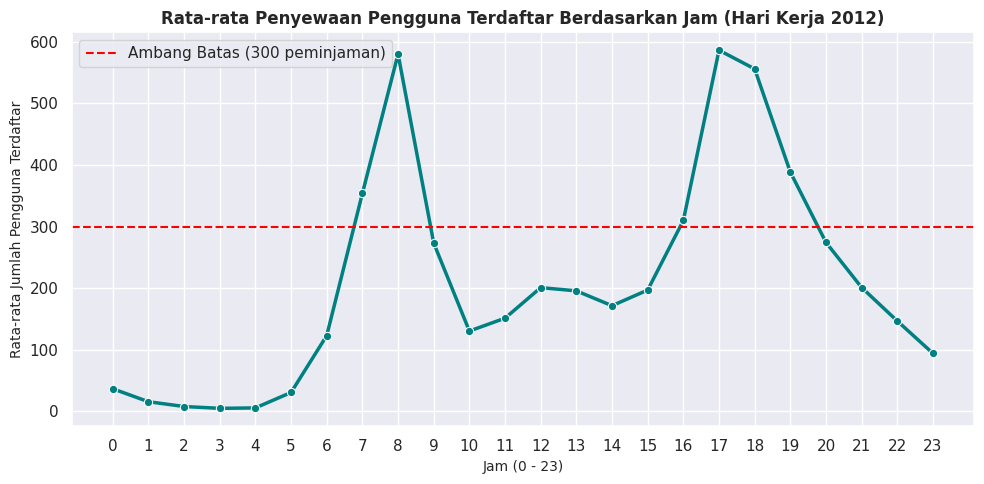

In [5]:
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=hourly_registered_2012,
    x='hr',
    y='registered',
    marker='o',
    color='teal',
    linewidth=2.5
)
plt.axhline(300, color='red', linestyle='--', label='Ambang Batas (300 peminjaman)')
plt.title('Rata-rata Penyewaan Pengguna Terdaftar Berdasarkan Jam (Hari Kerja 2012)', fontsize=12, fontweight='bold')
plt.xlabel('Jam (0 - 23)', fontsize=10)
plt.ylabel('Rata-rata Jumlah Pengguna Terdaftar', fontsize=10)
plt.xticks(range(0, 24))
plt.legend()
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Puncak penyewaan sepeda oleh pengguna terdaftar (registered) pada hari kerja di tahun 2012 terjadi secara signifikan pada jam berangkat kerja (pukul 07:00–08:00) dan jam pulang kerja (pukul 17:00–18:00), dengan rata-rata melebihi 550 peminjaman per jam.
- Aktivitas peminjaman terendah terjadi pada waktu dini hari (pukul 03:00–04:00) dengan rata-rata mendekati nol.

### Pertanyaan 2:

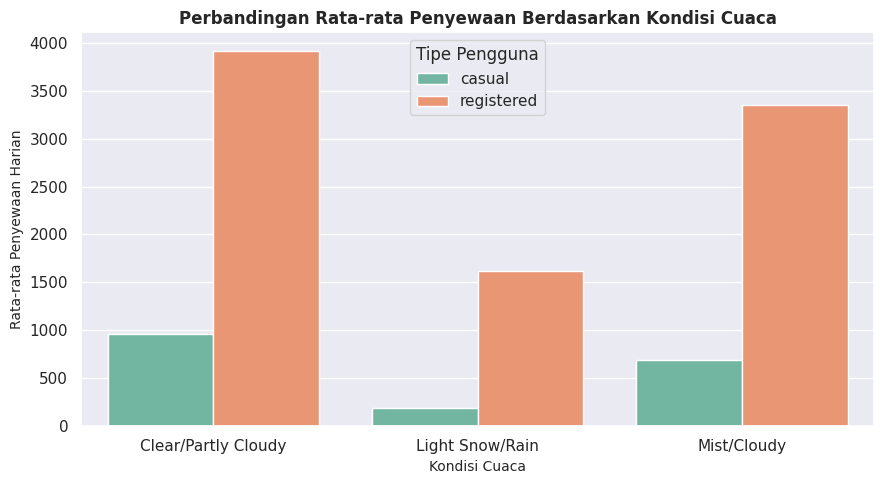

In [6]:
weather_melted = weather_user_df.melt(id_vars='weathersit_label', value_vars=['casual', 'registered'],
                                      var_name='User Type', value_name='Average Rental')

plt.figure(figsize=(9, 5))
sns.barplot(
    data=weather_melted,
    x='weathersit_label',
    y='Average Rental',
    hue='User Type',
    palette='Set2'
)
plt.title('Perbandingan Rata-rata Penyewaan Berdasarkan Kondisi Cuaca', fontsize=12, fontweight='bold')
plt.xlabel('Kondisi Cuaca', fontsize=10)
plt.ylabel('Rata-rata Penyewaan Harian', fontsize=10)
plt.legend(title='Tipe Pengguna')
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Kondisi cuaca cerah atau berawan Sebagian (Clear/Partly Cloudy) mendominasi jumlah penyewaan tertinggi harian, baik untuk pengguna kasual maupun terdaftar.
- Volume penyewaan sepeda mengalami penurunan yang sangat drastis pada kondisi cuaca buruk seperti salju atau hujan ringan (Light Snow/Rain).

###Pertanyaan 3:

/tmp/ipykernel_19520/2217181119.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


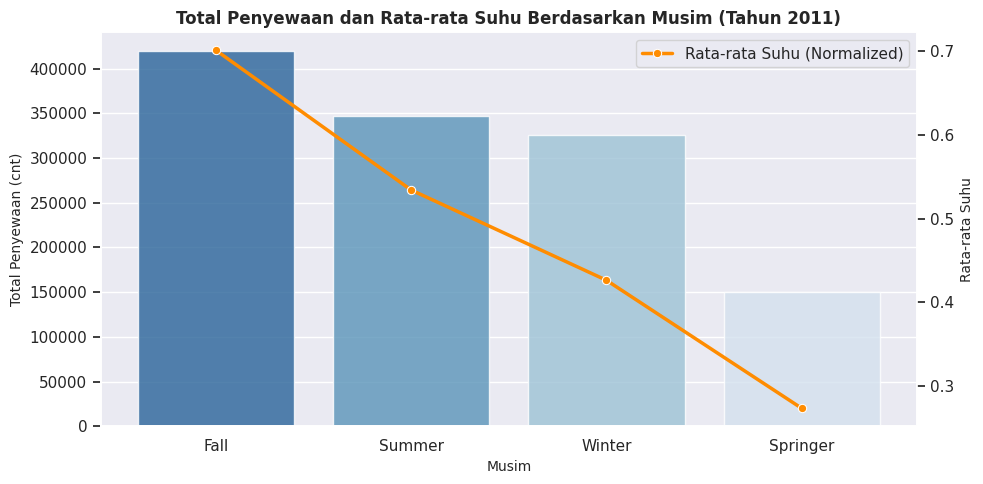

In [7]:
fig, ax1 = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=season_trend_2011,
    x='season_label',
    y='cnt',
    palette='Blues_r',
    ax=ax1,
    alpha=0.8
)
ax1.set_title('Total Penyewaan dan Rata-rata Suhu Berdasarkan Musim (Tahun 2011)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Musim', fontsize=10)
ax1.set_ylabel('Total Penyewaan (cnt)', fontsize=10)

ax2 = ax1.twinx()
sns.lineplot(
    data=season_trend_2011,
    x='season_label',
    y='temp',
    marker='o',
    color='darkorange',
    linewidth=2.5,
    ax=ax2,
    label='Rata-rata Suhu (Normalized)'
)
ax2.set_ylabel('Rata-rata Suhu', fontsize=10)
ax2.grid(False)

ax2.legend(loc='upper right')
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Musim Gugur (Fall) mencatatkan total akumulasi penyewaan sepeda tertinggi di tahun 2011, diikuti oleh Musim Panas (Summer), Musim Dingin (Winter), dan Musim Semi (Springer).
- Terdapat korelasi positif yang jelas antara rata-rata suhu harian dengan tingkat penyewaan; semakin tinggi suhu rata-rata suatu musim (seperti pada musim gugur dan panas), semakin tinggi pula minat masyarakat dalam menyewa sepeda.

## Analisis Lanjutan (Opsional)

/tmp/ipykernel_19520/4282993758.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


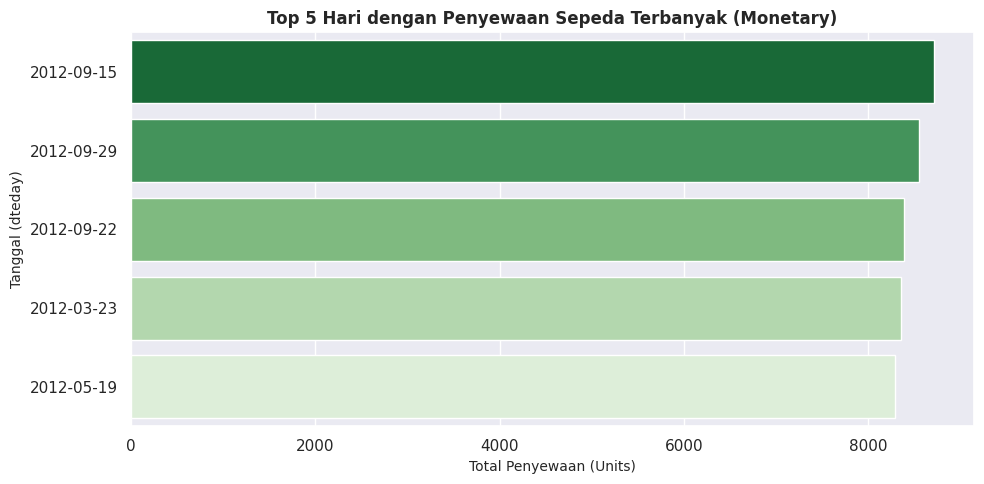

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

recent_date = day_df['dteday'].max()

rfm_df = day_df.groupby(by="dteday", as_index=False).agg({
    "cnt": "sum"
})

rfm_df["Recency"] = (recent_date - rfm_df["dteday"]).dt.days
rfm_df["Frequency"] = 1
rfm_df.rename(columns={"cnt": "Monetary"}, inplace=True)

plt.figure(figsize=(10, 5))
top_monetary = rfm_df.sort_values(by="Monetary", ascending=False).head(5)

sns.barplot(
    data=top_monetary,
    x="Monetary",
    y=top_monetary["dteday"].dt.strftime('%Y-%m-%d'),
    palette="Greens_r"
)

plt.title("Top 5 Hari dengan Penyewaan Sepeda Terbanyak (Monetary)", fontsize=12, fontweight='bold')
plt.xlabel("Total Penyewaan (Units)", fontsize=10)
plt.ylabel("Tanggal (dteday)", fontsize=10)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Recency: Mengukur keaktivan penyewaan sepeda berdasarkan jarak hari dari tanggal rekaman terakhir dalam dataset.
- Monetary: Berdasarkan indikator Monetary, dapat diidentifikasi 5 tanggal terbaik yang menghasilkan volume penyewaan sepeda tertinggi dalam seluruh rentang waktu operasional, di mana puncak penyewaan tertinggi harian berhasil mencapai lebih dari 8.700 transaksi dalam satu hari.
- Pemanfaatan Bisnis: Informasi tanggal puncak (peak days) ini membantu tim operasional untuk memprediksi hari-hari dengan permintaan super tinggi di masa depan guna mengoptimalkan distribusi dan pemeliharaan armada sepeda.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Lonjakan penyewaan tertinggi oleh pengguna registered pada hari kerja di tahun 2012 terjadi pada jam 08:00 pagi dan jam 17:00–18:00 sore (melewati ambang batas 300 peminjaman), yang merefleksikan jam berangkat dan pulang kerja.
- **Conclusion pertanyaan 2:** Terjadi penurunan drastis pada rata-rata penyewaan harian baik untuk pengguna casual maupun registered saat cuaca memburuk ke level 3 (Light Snow/Rain) dibandingkan saat cuaca cerah (Level 1).
- **Conclusion pertanyaan 3:** Musim Gugur (Fall) mencatatkan total akumulasi penyewaan sepeda tertinggi sepanjang tahun 2011, yang menunjukkan korelasi positif antara peningkatan rata-rata suhu harian dan tingginya aktivitas peminjaman.
- **Conclusion Analisis Lanjutan (RFM):** Berdasarkan analisis harian, teridentifikasi hari-hari puncak (peak days) dengan volume transaksi tertinggi yang mencapai lebih dari 8.700 unit dalam satu hari, memberikan kejelasan mengenai pola lonjakan permintaan bisnis secara makro.

**Rekomendasi Action Item:**
- Tim operasional harus memastikan ketersediaan armada sepeda penuh di stasiun-stasiun strategis pada pukul 07:00 pagi dan 16:00 sore di hari kerja untuk mengantisipasi lonjakan pengguna registered.
- Memberikan penawaran diskon khusus atau notifikasi promosi dalam aplikasi kepada pengguna casual saat cuaca cerah untuk mendongkrak tingkat okupansi.
- Berdasarkan temuan RFM, perusahaan dapat menjadwalkan perawatan atau perbaikan armada di luar hari-hari dengan volume tinggi agar tidak mengganggu operasional saat permintaan sedang berada di puncaknya.